### *Algoritmos Genéticos y Optimización Heurística - UTN-FRT*

# **Trabajo Práctico N°1**
### Tema: Generación de números aleatorios

***Integrantes***

*   Breslauer, León - 56340
*   Perez, Francisco - 56355



El siguiente código es para demostrar que no es adecuado usar "round" para generar numeros enteros aleatorios.

In [ ]:
import random
import math
import matplotlib.pyplot as plt

#CONSIGNA:
#generar N numeros ENTEROS aleatorios con probabilidad uniforme, entre a y b

def generar1(N, a, b):
  return [round(random.random()*(b-a)+a) for i in range(N)]

def generar2(N, a, b):
  return [int(random.random()*(1+b-a)+a) for i in range(N)]

def generar3(N, a, b):
  return [math.ceil(random.random()*(1+b-a)+a-1) for i in range(N)]

def generar4(N, a, b):
  return [random.randint(a, b) for i in range(N)]

#contar las veces que sale cada numero (cuantos numeros 0, cuantos 1, etc.)
def contar(vector, texto):
  n = max(vector)+1
  cantidad = [0]*n
  for i in vector:
      cantidad[i] = cantidad[i] + 1

  plt.bar(range(n), cantidad)
  plt.title(texto)
  plt.xlabel("Número")
  plt.ylabel("Cantidad de veces")
  plt.show()

Al generar con método con "round" la probabilidad no es uniforme (los extremos tienen una probabilidad menor). Con "int", en cambio, sí se logra una probabilidad uniforme.

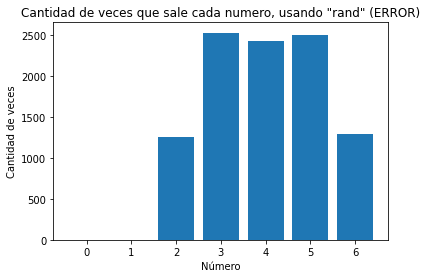

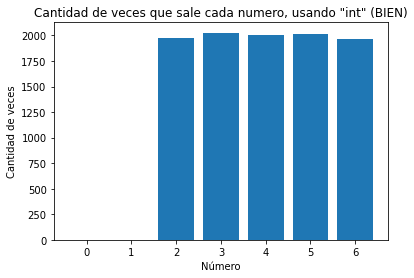

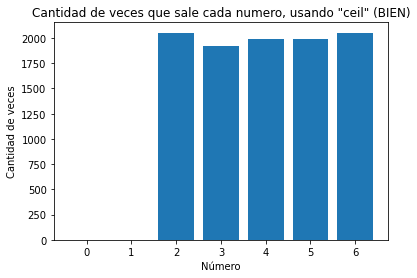

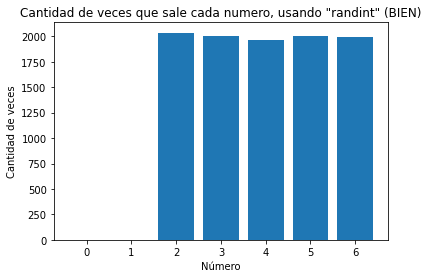

In [ ]:
N = 10000
vector = generar1(N, 2, 6)
contar(vector, 'Cantidad de veces que sale cada numero, usando "rand" (ERROR)')

vector = generar2(N, 2, 6)
contar(vector, 'Cantidad de veces que sale cada numero, usando "int" (BIEN)')

vector = generar3(N, 2, 6)
contar(vector, 'Cantidad de veces que sale cada numero, usando "ceil" (BIEN)')

vector = generar4(N, 2, 6)
contar(vector, 'Cantidad de veces que sale cada numero, usando "randint" (BIEN)')

# **Consignas**

La actividad presente solicita hacer uso de la notebook de generación y análisis de números aleatorios, para la cual se sugiere realizar diferentes corridas y sacar conclusiones del comportamiento observado. Considerar preguntas como:

    1. ¿Qué sucede con la distribución al tener poca cantidad de tiros?
    2. ¿Para cada caso (una misma configuración) se observa el mismo resultado de las distribuciones observadas?
    3. ¿Cuánta es la mínima cantidad de tiros donde se observa este efecto? 10-100-500-1000-10000.


# **Respuestas y conclusiones**

### *Respuestas a las preguntas 1-3*

1. Al realizar una cantidad pequeña de tiros (por ejemplo, N = 10 o N = 100), observamos que la distribución presenta mucho "ruido estadístico" debido a la alta variaza empírica. Por ello, las frecuencias en el histograma de ven muy desiguales para todos los métodos usados. Dicho de otra manera, cuando hacemos pocas pruebas, los resultados son desordenados por que se basan en la casualidad ocurrida en el intento (es decir, en algunos intentos se pueden generar más ciertos números, y en otros pueden generarse otros números con mayor frecuencia). Esto hace que la generación de los números sea impredecible y no uniforme, generando un histograma irregular cuando debería aproximadamente plano (todos los números generados con similar frecuencia). Además, esta irregularidad impide evaluar la calidad de la generación de números aleatorios por cada método.

2. No, en cada corrida las frecuencias exactas de ocurrencia de cada número varían. Sin embargo, si se prueban los métodos con un N lo suficientemente grande, la forma general de la distribución siempre se mantendrá plana y uniforme para los métodos correctos (int, ceil, randint), y con los extremos hundidos para el método erróneo (round).

3. El defecto de usar round para la generación de una distribución uniforme puede comenzar a insinuarse con 500 tiros, pero con 1000 tiros la asimetría en los extremos se nota más evidente.

### *Conclusiones*

Debido a que en este trabajo se utilizaron distintas estrategias para transformar una distribución continua en una distribución discreta (con números enteros), lo cual requiere de rigor matemáticos, presentamos el siguiente análisis de los métodos de generación de números aleatorios usados en este trabajo:

1. **Redondeo estándar usando** `round` **(función generar1)**: Es incorrecto usarlo debido a que el redondeo estándar genera intervalos de ocurrencia asimétricos. El rango que se mapea hacia los valores extremos (2 y 6 en este caso), tiene una amplitud de 0.5, mientras que el de los valores intermedios tiene una amplitud de 1.0. Por lo tanto, los extremos saldrán estadísticamente la mitad de las veces que el resto.

2. **Truncamiento con** `int` **(función generar2)**: Es adecuado usarlo ya que, al escalar el número aleatorio por (1+b-a) y al descartar los decimales con int, el algoritmo divide el espectro continuo en bloques idénticos de tamaño 1.0 para cada número. Esto último garantiza de que cada número entero tenga exactamente la misma probabilidad de aparecer.

3. **Ajuste de intervalo y redondeo hacia arriba con** `math.ceil` **(función generar3)**. Es adecuado usarlo dado que, al ajustar los límites del intervalo de ocurrencia continua con la expresión (1+b-a)+a-1 para formar el intervalo abierto (1,6), y luego truncando los números continuos para formar números enteros, se garantiza que cada uno de estos últimos tenga exactamente la misma posibilidad de aparecer (la amplitud del rango de ocurrencia es igual a 1.0). Sin embargo, al igual que con la estrategia 2, la expresión algebraica utilizada es compleja de comprender a simple vista, es menos legible y propensa a errores para implementarse.

4. **Método nativo con** `random.randint` **(función generar4)**. Es la alternativa correcta de usar dado que es la herramienta proporcionada por la biblioteca estándar de Python, y está diseñada exclusivamente para devolver enteros con probabilidad uniforme. Usándola, nos ahorramos de cometer errores aritméticos manuales, el código se vuelve más semántico y aprovechamos la optimización interna del lenguaje.